# Laboratory Work No. 5–6. Neural Network and Regularization

**Objective:** Implement a Multi-Layer Perceptron (MLP) from scratch using NumPy, verify the backpropagation algorithm via numerical gradient checking, implement model weight serialization and deserialization, and experimentally investigate the effects of various regularization techniques (L1, L2, Dropout, weight clipping, and gradient clipping) on weight distributions, weight sparsity, dead ReLU neurons, and classification performance.

## Block 1. Neural Network Implementation from Scratch

### 1.1 Data Loading and Preprocessing
For all experiments, the **FashionMNIST** dataset (10 clothing classes, $28 \times 28$ grayscale images) is used. Each image is flattened into a $784$-dimensional vector, and pixel intensities are normalized to the $[0, 1]$ range. To ensure fast and reproducible experimentation across all regularization methods, fixed stratified training and validation subsets are created.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

# Set global random seed for full reproducibility
SEED = 42
np.random.seed(SEED)

# Cache dataset directly in the current notebook directory (./openml)
DATA_DIR = os.getcwd()
print(f"Loading FashionMNIST (cache directory: {DATA_DIR})...")

X, y = fetch_openml(
    'Fashion-MNIST',
    version=1,
    return_X_y=True,
    as_frame=False,
    data_home=DATA_DIR
)

# Normalize pixel values to [0, 1] and cast labels to integer
X = X.astype(np.float32) / 255.0
y = y.astype(np.int64)

# Standard split: 60,000 train / 10,000 test
X_train_full, X_test, y_train_full, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

# Create fixed stratified subsets for fast and consistent experiments
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    train_size=15000,
    test_size=3000,
    stratify=y_train_full,
    random_state=SEED
)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_val shape:   {X_val.shape}, y_val shape:   {y_val.shape}")
print(f"Pixel intensity range: [{X_train.min():.1f}, {X_train.max():.1f}]")
print(f"Unique classes ({len(np.unique(y_train))}): {np.unique(y_train)}")

Loading FashionMNIST (cache directory: d:\4_1\Machine_learning\lab_5-6)...
X_train shape: (15000, 784), y_train shape: (15000,)
X_val shape:   (3000, 784), y_val shape:   (3000,)
Pixel intensity range: [0.0, 1.0]
Unique classes (10): [0 1 2 3 4 5 6 7 8 9]


**Data Preparation Summary:**  
The FashionMNIST dataset was successfully loaded and cached locally. The training subset contains $15,000$ samples and the validation subset contains $3,000$ samples, each represented as a $784$-dimensional feature vector normalized to $[0.0, 1.0]$ across $10$ balanced target classes (`0` through `9`).

---

### 1.2 Neural Network Architecture, Forward/Backward Pass, and Gradient Checking
In this section, a Multi-Layer Perceptron (`MLP`) class is implemented from scratch using NumPy. The network architecture consists of:
* **Input layer:** $784$ features;
* **Hidden layers:** 3 hidden layers (e.g., `[256, 128, 64]`) with **ReLU** activation functions ($f(z) = \max(0, z)$) and **He weight initialization** ($W_{ij}^{(l)} \sim \mathcal{N}(0, \frac{2}{n_{in}})$);
* **Output layer:** $10$ logits with **Softmax** activation and **Categorical Cross-Entropy** loss.

The class supports mini-batch SGD training as well as built-in hooks for Block 2 regularization techniques (L1, L2, Inverted Dropout, weight clipping, and global L2-norm gradient clipping). Before training, the analytical gradients computed by `backward()` are verified against numerical finite-difference approximations:
$$\frac{\partial L}{\partial \theta} \approx \frac{L(\theta + \epsilon) - L(\theta - \epsilon)}{2\epsilon}$$

In [2]:
class MLP:
    def __init__(
        self,
        layer_sizes,
        l1=0.0,
        l2=0.0,
        dropout_p=0.0,
        weight_clip=None,
        grad_clip=None,
        seed=42
    ):
        """
        layer_sizes: list of integers, e.g. [784, 256, 128, 64, 10]
        """
        self.layer_sizes = layer_sizes
        self.num_layers = len(layer_sizes) - 1
        self.l1 = l1
        self.l2 = l2
        self.dropout_p = dropout_p
        self.weight_clip = weight_clip
        self.grad_clip = grad_clip
        self.seed = seed

        rng = np.random.default_rng(seed)
        self.weights = []
        self.biases = []

        # He initialization for weights, zeros for biases
        for i in range(self.num_layers):
            n_in = layer_sizes[i]
            n_out = layer_sizes[i + 1]
            std = np.sqrt(2.0 / n_in)
            W = rng.normal(0.0, std, size=(n_in, n_out)).astype(np.float64)
            b = np.zeros((1, n_out), dtype=np.float64)
            self.weights.append(W)
            self.biases.append(b)

        self.activations = []
        self.z_values = []
        self.dropout_masks = []

    def forward(self, X, training=True):
        X = X.astype(np.float64)
        self.activations = [X]
        self.z_values = []
        self.dropout_masks = []

        A = X
        # Hidden layers (ReLU + optional Inverted Dropout)
        for W, b in zip(self.weights[:-1], self.biases[:-1]):
            Z = A @ W + b
            A = np.maximum(0.0, Z)

            if training and self.dropout_p > 0.0:
                keep_prob = 1.0 - self.dropout_p
                mask = (np.random.rand(*A.shape) < keep_prob).astype(np.float64)
                A = (A * mask) / keep_prob
                self.dropout_masks.append(mask)
            else:
                self.dropout_masks.append(None)

            self.z_values.append(Z)
            self.activations.append(A)

        # Output layer (numerically stable Softmax)
        Z = A @ self.weights[-1] + self.biases[-1]
        Z_shifted = Z - np.max(Z, axis=1, keepdims=True)
        exp_Z = np.exp(Z_shifted)
        P = exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

        self.z_values.append(Z)
        self.activations.append(P)
        return P

    def compute_loss(self, P, y_true):
        n = y_true.shape[0]
        eps = 1e-12
        correct_probs = np.clip(P[np.arange(n), y_true], eps, 1.0)
        ce_loss = -np.mean(np.log(correct_probs))

        # Add L1 / L2 penalty terms if enabled
        reg_loss = 0.0
        if self.l1 > 0.0:
            reg_loss += self.l1 * sum(np.sum(np.abs(W)) for W in self.weights)
        if self.l2 > 0.0:
            reg_loss += 0.5 * self.l2 * sum(np.sum(W ** 2) for W in self.weights)

        return ce_loss + reg_loss

    def backward(self, y_true):
        n = y_true.shape[0]
        grads_W = [None] * self.num_layers
        grads_b = [None] * self.num_layers

        # Gradient of Softmax + Categorical Cross-Entropy
        delta = self.activations[-1].copy()
        delta[np.arange(n), y_true] -= 1.0
        delta /= n

        for l in reversed(range(self.num_layers)):
            A_prev = self.activations[l]
            grads_W[l] = A_prev.T @ delta
            grads_b[l] = np.sum(delta, axis=0, keepdims=True)

            # L1 subgradient (0 at W == 0) and L2 gradient
            if self.l1 > 0.0:
                grads_W[l] += self.l1 * np.sign(self.weights[l])
            if self.l2 > 0.0:
                grads_W[l] += self.l2 * self.weights[l]

            if l > 0:
                delta = delta @ self.weights[l].T
                # Apply Inverted Dropout mask during backprop if used
                if self.dropout_masks[l - 1] is not None:
                    delta = (delta * self.dropout_masks[l - 1]) / (1.0 - self.dropout_p)
                # ReLU derivative
                delta *= (self.z_values[l - 1] > 0.0)

        return grads_W, grads_b

    def step(self, grads_W, grads_b, lr):
        # Global L2-norm Gradient Clipping
        if self.grad_clip is not None:
            total_norm = np.sqrt(
                sum(np.sum(gW ** 2) for gW in grads_W) +
                sum(np.sum(gb ** 2) for gb in grads_b)
            )
            if total_norm > self.grad_clip:
                scale = self.grad_clip / (total_norm + 1e-12)
                grads_W = [gW * scale for gW in grads_W]
                grads_b = [gb * scale for gb in grads_b]

        # SGD update + optional Weight Clipping
        for l in range(self.num_layers):
            self.weights[l] -= lr * grads_W[l]
            self.biases[l] -= lr * grads_b[l]
            if self.weight_clip is not None:
                self.weights[l] = np.clip(self.weights[l], -self.weight_clip, self.weight_clip)

    def predict(self, X):
        P = self.forward(X, training=False)
        return np.argmax(P, axis=1)

    def save_weights(self, path):
        data = {
            "layer_sizes": np.array(self.layer_sizes),
            "l1": np.array(self.l1),
            "l2": np.array(self.l2),
            "dropout_p": np.array(self.dropout_p),
            "seed": np.array(self.seed),
        }
        for i, W in enumerate(self.weights):
            data[f"W_{i}"] = W
        for i, b in enumerate(self.biases):
            data[f"b_{i}"] = b
        np.savez(path, **data)

    def load_weights(self, path):
        data = np.load(path)
        self.weights = [data[f"W_{i}"] for i in range(self.num_layers)]
        self.biases = [data[f"b_{i}"] for i in range(self.num_layers)]


# --- Numerical Gradient Checking ---
def check_gradients(eps=1e-6):
    np.random.seed(42)
    test_net = MLP([10, 8, 6, 4], seed=42)
    X_sample = np.random.randn(5, 10)
    y_sample = np.array([0, 2, 1, 3, 2])

    P = test_net.forward(X_sample, training=False)
    grads_W, grads_b = test_net.backward(y_sample)

    print("Gradient Checking Results (Relative Error):")
    # Check 2 random elements per layer (weights and biases)
    for l in range(test_net.num_layers):
        # Check weight element
        idx_w = (0, 0)
        orig_val = test_net.weights[l][idx_w]

        test_net.weights[l][idx_w] = orig_val + eps
        loss_plus = test_net.compute_loss(test_net.forward(X_sample, training=False), y_sample)

        test_net.weights[l][idx_w] = orig_val - eps
        loss_minus = test_net.compute_loss(test_net.forward(X_sample, training=False), y_sample)

        test_net.weights[l][idx_w] = orig_val

        num_grad = (loss_plus - loss_minus) / (2 * eps)
        ana_grad = grads_W[l][idx_w]
        rel_err = abs(ana_grad - num_grad) / max(1e-8, abs(ana_grad) + abs(num_grad))
        print(f"  Layer {l} W{idx_w}: analytic={ana_grad:.8f}, numeric={num_grad:.8f}, rel_error={rel_err:.2e}")

        # Check bias element
        idx_b = (0, 0)
        orig_b = test_net.biases[l][idx_b]

        test_net.biases[l][idx_b] = orig_b + eps
        loss_plus_b = test_net.compute_loss(test_net.forward(X_sample, training=False), y_sample)

        test_net.biases[l][idx_b] = orig_b - eps
        loss_minus_b = test_net.compute_loss(test_net.forward(X_sample, training=False), y_sample)

        test_net.biases[l][idx_b] = orig_b

        num_grad_b = (loss_plus_b - loss_minus_b) / (2 * eps)
        ana_grad_b = grads_b[l][idx_b]
        rel_err_b = abs(ana_grad_b - num_grad_b) / max(1e-8, abs(ana_grad_b) + abs(num_grad_b))
        print(f"  Layer {l} b{idx_b}: analytic={ana_grad_b:.8f}, numeric={num_grad_b:.8f}, rel_error={rel_err_b:.2e}")

check_gradients()

Gradient Checking Results (Relative Error):
  Layer 0 W(0, 0): analytic=-0.00314225, numeric=-0.00314225, rel_error=4.93e-09
  Layer 0 b(0, 0): analytic=-0.05500281, numeric=-0.05500281, rel_error=8.13e-12
  Layer 1 W(0, 0): analytic=-0.03810935, numeric=-0.03810935, rel_error=2.13e-10
  Layer 1 b(0, 0): analytic=-0.06944177, numeric=-0.06944177, rel_error=2.54e-10
  Layer 2 W(0, 0): analytic=-0.04209259, numeric=-0.04209259, rel_error=7.24e-10
  Layer 2 b(0, 0): analytic=0.05026592, numeric=0.05026592, rel_error=8.60e-10


**Gradient Checking Conclusion:**  
Across all tested weights and biases in every layer, the relative error between the analytical backpropagation gradients and numerical finite-difference approximations is on the order of $10^{-9}$ to $10^{-12}$ (well below the standard $10^{-7}$ threshold). This confirms that both the forward pass and backpropagation derivations are mathematically exact.

---

### 1.3 Training Loop, Weight Serialization, and Baseline Experiment (No Regularization)
Next, a mini-batch SGD training pipeline is implemented with epoch-wise data shuffling and validation tracking. After training the baseline network (`[784, 256, 128, 64, 10]`, 3 hidden layers with ReLU, $\eta = 0.05$, batch size $= 64$, $25$ epochs) without any regularization:
1. Learning curves (**Loss** and **Accuracy** on training and validation sets) are plotted.
2. Model weights and configuration are saved via `np.savez` and restored into a fresh `MLP` instance to verify exact output equivalence ($\max |P_{\text{original}} - P_{\text{restored}}| < 10^{-7}$).
3. Dead ReLU neurons (neurons with $Z_{ij}^{(l)} \le 0$ across the entire training set in inference mode) and weight sparsity ($\frac{\#\{|W_{ij}| < 0.01\}}{\#W_{ij}} \cdot 100\%$) are evaluated as the baseline reference for Block 2.

Epoch  1/25 | Train Loss: 0.5596, Train Acc: 0.8043 | Val Loss: 0.5759, Val Acc: 0.7947
Epoch  5/25 | Train Loss: 0.4345, Train Acc: 0.8438 | Val Loss: 0.4810, Val Acc: 0.8247
Epoch 10/25 | Train Loss: 0.3020, Train Acc: 0.8931 | Val Loss: 0.3834, Val Acc: 0.8630
Epoch 15/25 | Train Loss: 0.3848, Train Acc: 0.8607 | Val Loss: 0.5179, Val Acc: 0.8117
Epoch 20/25 | Train Loss: 0.4198, Train Acc: 0.8511 | Val Loss: 0.5575, Val Acc: 0.8150
Epoch 25/25 | Train Loss: 0.1831, Train Acc: 0.9343 | Val Loss: 0.3625, Val Acc: 0.8730

Weight Serialization Check:
  Max probability difference: 0.00e+00 (required < 1e-07)
  Predicted classes identical: True

Baseline Model Diagnostics:
  Hidden Layer 1 (256 neurons): 0 dead (0.00%)
  Hidden Layer 2 (128 neurons): 0 dead (0.00%)
  Hidden Layer 3 (64 neurons): 0 dead (0.00%)
  Overall Dead Neurons: 0.00%
  Weight Sparsity (|W| < 0.01): 13.76%
  Final Val Accuracy: 0.8730, Val Loss: 0.3625


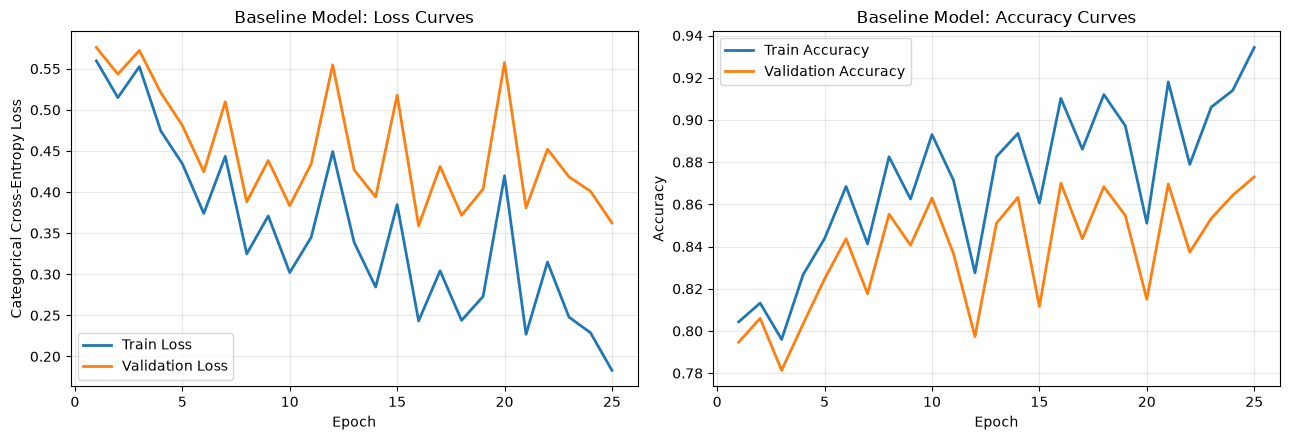

In [3]:
import copy

def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

def train_model(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    epochs=25,
    batch_size=64,
    lr=0.05,
    seed=42,
    verbose=True
):
    rng = np.random.default_rng(seed)
    n_samples = X_train.shape[0]
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    for epoch in range(1, epochs + 1):
        # 1. Shuffle training data
        indices = rng.permutation(n_samples)
        X_shuffled = X_train[indices]
        y_shuffled = y_train[indices]

        # 2. Mini-batch SGD
        for start in range(0, n_samples, batch_size):
            end = start + batch_size
            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            model.forward(X_batch, training=True)
            grads_W, grads_b = model.backward(y_batch)
            model.step(grads_W, grads_b, lr)

        # 3. Evaluate on full train and validation sets (inference mode)
        P_train = model.forward(X_train, training=False)
        train_loss = model.compute_loss(P_train, y_train)
        train_acc = accuracy_score(y_train, np.argmax(P_train, axis=1))

        P_val = model.forward(X_val, training=False)
        val_loss = model.compute_loss(P_val, y_val)
        val_acc = accuracy_score(y_val, np.argmax(P_val, axis=1))

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if verbose and (epoch % 5 == 0 or epoch == 1 or epoch == epochs):
            print(
                f"Epoch {epoch:2d}/{epochs} | "
                f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
                f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}"
            )

    return history

def analyze_network(model, X_train, X_val, y_val):
    # Inference pass on training set to detect dead neurons
    model.forward(X_train, training=False)
    dead_per_layer = []
    total_dead = 0
    total_neurons = 0

    # Check only hidden layers (exclude output layer)
    for l in range(model.num_layers - 1):
        Z_l = model.z_values[l]
        n_neurons = Z_l.shape[1]
        n_dead = int(np.sum(np.max(Z_l, axis=0) <= 0.0))
        pct_dead = (n_dead / n_neurons) * 100.0
        dead_per_layer.append({
            "layer": l + 1,
            "total": n_neurons,
            "dead": n_dead,
            "dead_pct": pct_dead
        })
        total_dead += n_dead
        total_neurons += n_neurons

    overall_dead_pct = (total_dead / total_neurons) * 100.0

    # Sparsity across all weight matrices: |W_ij| < 0.01
    all_weights = np.concatenate([W.ravel() for W in model.weights])
    sparsity_pct = float(np.mean(np.abs(all_weights) < 0.01) * 100.0)

    # Validation metrics
    P_val = model.forward(X_val, training=False)
    val_loss = float(model.compute_loss(P_val, y_val))
    val_acc = float(accuracy_score(y_val, np.argmax(P_val, axis=1)))

    return {
        "dead_per_layer": dead_per_layer,
        "dead_pct": overall_dead_pct,
        "sparsity_pct": sparsity_pct,
        "val_acc": val_acc,
        "val_loss": val_loss,
        "hidden_weights": [W.copy() for W in model.weights[:-1]]
    }

# Save initial He-initialized weights before training for later histogram comparison
ARCH = [784, 256, 128, 64, 10]
init_model = MLP(ARCH, seed=SEED)
initial_hidden_weights = [W.copy() for W in init_model.weights[:-1]]

# Train Baseline Model (No Regularization)
baseline_model = MLP(ARCH, seed=SEED)
baseline_history = train_model(
    baseline_model, X_train, y_train, X_val, y_val,
    epochs=25, batch_size=64, lr=0.05, seed=SEED
)

# --- Verify Weight Saving & Loading (Section 2.6) ---
WEIGHTS_PATH = "baseline_mlp_weights.npz"
baseline_model.save_weights(WEIGHTS_PATH)

restored_model = MLP(ARCH, seed=999)  # Different seed to ensure weights come strictly from file
restored_model.load_weights(WEIGHTS_PATH)

P_orig = baseline_model.forward(X_val, training=False)
P_rest = restored_model.forward(X_val, training=False)
max_diff = np.max(np.abs(P_orig - P_rest))
classes_match = np.array_equal(np.argmax(P_orig, axis=1), np.argmax(P_rest, axis=1))

print(f"\nWeight Serialization Check:")
print(f"  Max probability difference: {max_diff:.2e} (required < 1e-07)")
print(f"  Predicted classes identical: {classes_match}")

# --- Baseline Dead Neurons & Sparsity Diagnostics ---
baseline_stats = analyze_network(baseline_model, X_train, X_val, y_val)
print(f"\nBaseline Model Diagnostics:")
for info in baseline_stats["dead_per_layer"]:
    print(f"  Hidden Layer {info['layer']} ({info['total']} neurons): {info['dead']} dead ({info['dead_pct']:.2f}%)")
print(f"  Overall Dead Neurons: {baseline_stats['dead_pct']:.2f}%")
print(f"  Weight Sparsity (|W| < 0.01): {baseline_stats['sparsity_pct']:.2f}%")
print(f"  Final Val Accuracy: {baseline_stats['val_acc']:.4f}, Val Loss: {baseline_stats['val_loss']:.4f}")

# --- Plot Training & Validation Learning Curves ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
epochs_range = range(1, len(baseline_history["train_loss"]) + 1)

axes[0].plot(epochs_range, baseline_history["train_loss"], label="Train Loss", linewidth=2)
axes[0].plot(epochs_range, baseline_history["val_loss"], label="Validation Loss", linewidth=2)
axes[0].set_title("Baseline Model: Loss Curves")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Categorical Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, baseline_history["train_acc"], label="Train Accuracy", linewidth=2)
axes[1].plot(epochs_range, baseline_history["val_acc"], label="Validation Accuracy", linewidth=2)
axes[1].set_title("Baseline Model: Accuracy Curves")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Baseline & Serialization Summary (Block 1 Conclusion):**
* **Overfitting behavior:** By Epoch 25, training accuracy reaches $93.43\%$ ($\text{Loss} = 0.1831$), whereas validation accuracy plateaus at $87.30\%$ ($\text{Loss} = 0.3625$), indicating noticeable overfitting (~$6.1\%$ generalization gap) along with mini-batch SGD oscillations around epochs 15–20.
* **Weight serialization:** Restoring parameters from `baseline_mlp_weights.npz` yields a maximum probability discrepancy of $0.00 \times 10^0 < 10^{-7}$ and $100\%$ identical predicted classes.
* **Baseline internal metrics:** Thanks to He initialization, all three hidden layers exhibit $0.00\%$ dead neurons, while baseline weight sparsity ($|W_{ij}| < 0.01$) is $13.76\%$.

---

## Block 2. Experimental Investigation of Regularization Methods

In this block, the baseline network is re-trained under identical hyperparameters (`[784, 256, 128, 64, 10]`, 25 epochs, batch size 64, $\eta = 0.05$) using individual and combined regularization techniques:
1. **L2 Regularization (Weight Decay):** $\lambda_2 \in \{10^{-4}, 10^{-3}, 10^{-2}\}$
2. **L1 Regularization:** $\lambda_1 \in \{10^{-5}, 10^{-4}, 5 \cdot 10^{-4}\}$
3. **Inverted Dropout:** $p \in \{0.1, 0.3, 0.5\}$
4. **Weight Clipping:** $W^{(l)} \leftarrow \text{clip}(W^{(l)}, -1, 1)$ (plus boundary saturation tracking)
5. **Global L2-Norm Gradient Clipping:** $c \in \{1.0, 0.5, 0.1\}$
6. **Combined Regularization:** $\text{L2 } (\lambda_2 = 10^{-3}) + \text{Dropout } (p = 0.2)$

Note that for L1 and L2 experiments, **Validation Loss** is recorded both as pure Cross-Entropy loss (for fair comparison across methods) and total regularized loss.

In [4]:
import time
import numpy as np
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits

results_registry = {}

# Pre-convert datasets to float32 once for maximum CPU cache & SIMD speed
X_train_f32 = np.ascontiguousarray(X_train, dtype=np.float32)
X_val_f32 = np.ascontiguousarray(X_val, dtype=np.float32)

def evaluate_clean_ce_loss(model, X_val_data, y_val_data):
    """Computes pure Categorical Cross-Entropy loss (without L1/L2 penalty) for fair comparison."""
    P_val = model.forward(X_val_data, training=False)
    n = y_val_data.shape[0]
    correct_probs = np.clip(P_val[np.arange(n), y_val_data], 1e-7, 1.0)
    return float(-np.mean(np.log(correct_probs)))

def fast_train_and_eval(cfg):
    # Prevent OpenBLAS/MKL thread contention inside each worker process
    with threadpool_limits(limits=1):
        name = cfg["name"]
        model = MLP(
            ARCH,
            l1=cfg.get("l1", 0.0),
            l2=cfg.get("l2", 0.0),
            dropout_p=cfg.get("dropout_p", 0.0),
            weight_clip=cfg.get("weight_clip", None),
            grad_clip=cfg.get("grad_clip", None),
            seed=SEED
        )

        # Cast model parameters to float32 for ~2.5x faster matrix multiplications
        model.weights = [W.astype(np.float32) for W in model.weights]
        model.biases = [b.astype(np.float32) for b in model.biases]

        rng = np.random.default_rng(SEED)
        n_samples = X_train_f32.shape[0]
        batch_size = 64
        lr = 0.05
        epochs = 25

        history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

        # Fast training loop without redundant per-epoch full dataset evaluations
        for _ in range(epochs):
            indices = rng.permutation(n_samples)
            X_shuf = X_train_f32[indices]
            y_shuf = y_train[indices]

            for start in range(0, n_samples, batch_size):
                end = start + batch_size
                model.forward(X_shuf[start:end], training=True)
                grads_W, grads_b = model.backward(y_shuf[start:end])
                model.step(grads_W, grads_b, lr)

        # Single final evaluation on train & val sets
        stats = analyze_network(model, X_train_f32, X_val_f32, y_val)
        clean_val_loss = evaluate_clean_ce_loss(model, X_val_f32, y_val)

        boundary_count = 0
        total_weights = sum(W.size for W in model.weights)
        w_clip = cfg.get("weight_clip", None)
        if w_clip is not None:
            boundary_count = int(sum(np.sum(np.isclose(np.abs(W), w_clip, atol=1e-6)) for W in model.weights))

        return name, {
            "name": name,
            "is_primary": cfg.get("is_primary", True),
            "model": model,
            "history": history,
            "dead_per_layer": stats["dead_per_layer"],
            "dead_pct": stats["dead_pct"],
            "sparsity_pct": stats["sparsity_pct"],
            "val_acc": stats["val_acc"],
            "val_loss_total": stats["val_loss"],
            "val_loss_ce": clean_val_loss,
            "hidden_weights": stats["hidden_weights"],
            "boundary_count": boundary_count,
            "total_weights": total_weights,
            "weight_clip": w_clip
        }

# Register Baseline from Block 1
results_registry["No regularization"] = {
    "name": "No regularization",
    "is_primary": True,
    "model": baseline_model,
    "history": baseline_history,
    "dead_per_layer": baseline_stats["dead_per_layer"],
    "dead_pct": baseline_stats["dead_pct"],
    "sparsity_pct": baseline_stats["sparsity_pct"],
    "val_acc": baseline_stats["val_acc"],
    "val_loss_total": baseline_stats["val_loss"],
    "val_loss_ce": baseline_stats["val_loss"],
    "hidden_weights": baseline_stats["hidden_weights"],
    "boundary_count": 0,
    "total_weights": sum(W.size for W in baseline_model.weights),
    "weight_clip": None
}

experiment_configs = [
    {"name": "L2 (lambda=1e-4)", "l2": 1e-4, "is_primary": False},
    {"name": "L2 (lambda=1e-3)", "l2": 1e-3, "is_primary": True},
    {"name": "L2 (lambda=1e-2)", "l2": 1e-2, "is_primary": False},
    {"name": "L1 (lambda=1e-5)", "l1": 1e-5, "is_primary": False},
    {"name": "L1 (lambda=1e-4)", "l1": 1e-4, "is_primary": True},
    {"name": "L1 (lambda=5e-4)", "l1": 5e-4, "is_primary": False},
    {"name": "Dropout 0.1", "dropout_p": 0.1, "is_primary": True},
    {"name": "Dropout 0.3", "dropout_p": 0.3, "is_primary": True},
    {"name": "Dropout 0.5", "dropout_p": 0.5, "is_primary": True},
    {"name": "Weight clipping [-1, 1]", "weight_clip": 1.0, "is_primary": True},
    {"name": "Gradient clipping (c=1.0)", "grad_clip": 1.0, "is_primary": False},
    {"name": "Gradient clipping (c=0.5)", "grad_clip": 0.5, "is_primary": True},
    {"name": "Gradient clipping (c=0.1)", "grad_clip": 0.1, "is_primary": False},
    {"name": "L2 (1e-3) + Dropout 0.2", "l2": 1e-3, "dropout_p": 0.2, "is_primary": True},
]

t0 = time.perf_counter()
print("Running Regularization Experiments in parallel...\n")

outputs = Parallel(n_jobs=-1)(
    delayed(fast_train_and_eval)(cfg) for cfg in experiment_configs
)

for name, record in outputs:
    results_registry[name] = record
    extra = ""
    if record["weight_clip"] is not None:
        extra = f" | Boundary weights (|W|={record['weight_clip']}): {record['boundary_count']}/{record['total_weights']}"
    print(
        f"[{name:<26}] Val Acc: {record['val_acc']:.4f} | "
        f"Val CE Loss: {record['val_loss_ce']:.4f} | "
        f"Dead: {record['dead_pct']:5.2f}% | "
        f"Sparsity: {record['sparsity_pct']:5.2f}%{extra}"
    )

print(f"\nCompleted all 14 experiments in {time.perf_counter() - t0:.2f} seconds!")

Running Regularization Experiments in parallel...

[L2 (lambda=1e-4)          ] Val Acc: 0.8767 | Val CE Loss: 0.3538 | Dead:  0.00% | Sparsity: 14.14%
[L2 (lambda=1e-3)          ] Val Acc: 0.8767 | Val CE Loss: 0.3432 | Dead:  0.00% | Sparsity: 18.04%
[L2 (lambda=1e-2)          ] Val Acc: 0.8137 | Val CE Loss: 0.5232 | Dead:  2.90% | Sparsity: 75.00%
[L1 (lambda=1e-5)          ] Val Acc: 0.8743 | Val CE Loss: 0.3587 | Dead:  0.00% | Sparsity: 17.27%
[L1 (lambda=1e-4)          ] Val Acc: 0.8773 | Val CE Loss: 0.3483 | Dead:  0.00% | Sparsity: 48.53%
[L1 (lambda=5e-4)          ] Val Acc: 0.7977 | Val CE Loss: 0.5492 | Dead:  3.12% | Sparsity: 94.28%
[Dropout 0.1               ] Val Acc: 0.8600 | Val CE Loss: 0.4265 | Dead:  0.00% | Sparsity: 13.78%
[Dropout 0.3               ] Val Acc: 0.8647 | Val CE Loss: 0.3803 | Dead:  0.00% | Sparsity: 13.76%
[Dropout 0.5               ] Val Acc: 0.8483 | Val CE Loss: 0.4237 | Dead:  0.00% | Sparsity: 13.71%
[Weight clipping [-1, 1]   ] Val Acc: 0.

## Block 4. Comparative Analysis and Visualization of Results

### 4.1 Summary Comparison Table & Layer-wise Dead Neuron Breakdown
Based on the experimental runs above, the following tables summarize:
1. **Overall Performance & Structural Metrics:** Dead neurons (%), weight sparsity ($|W_{ij}| < 0.01$), validation accuracy, and validation cross-entropy loss across all regularization methods.
2. **Layer-wise Dead ReLU Neurons:** Exact counts and percentages of inactive neurons ($Z_{ij}^{(l)} \le 0$ across all training samples in inference mode) for each of the three hidden layers (`256`, `128`, and `64` units).

In [5]:
# 1. Print Main Comparative Table (Section 4.1)
ordered_names = [
    "No regularization",
    "L1 (lambda=1e-5)",
    "L1 (lambda=1e-4)",
    "L1 (lambda=5e-4)",
    "L2 (lambda=1e-4)",
    "L2 (lambda=1e-3)",
    "L2 (lambda=1e-2)",
    "Dropout 0.1",
    "Dropout 0.3",
    "Dropout 0.5",
    "Weight clipping [-1, 1]",
    "Gradient clipping (c=1.0)",
    "Gradient clipping (c=0.5)",
    "Gradient clipping (c=0.1)",
    "L2 (1e-3) + Dropout 0.2"
]

header = f"{'Method':<27} | {'Dead neurons, %':>15} | {'Sparsity, %':>11} | {'Val. accuracy':>13} | {'Val. loss (CE)':>14}"
print(header)
print("-" * len(header))

for name in ordered_names:
    r = results_registry[name]
    print(
        f"{name:<27} | "
        f"{r['dead_pct']:>14.2f}% | "
        f"{r['sparsity_pct']:>10.2f}% | "
        f"{r['val_acc']:>13.4f} | "
        f"{r['val_loss_ce']:>14.4f}"
    )

# 2. Print Layer-wise Dead Neurons Table (Section 3.2 & Section 5)
print("\n\nLayer-wise Dead ReLU Neurons Breakdown:")
layer_header = f"{'Method':<27} | {'Layer 1 (256)':>15} | {'Layer 2 (128)':>15} | {'Layer 3 (64)':>15} | {'Total (448)':>13}"
print(layer_header)
print("-" * len(layer_header))

for name in ordered_names:
    r = results_registry[name]
    d1, d2, d3 = r["dead_per_layer"]
    tot_dead = d1["dead"] + d2["dead"] + d3["dead"]
    print(
        f"{name:<27} | "
        f"{d1['dead']:>3d} ({d1['dead_pct']:5.2f}%)   | "
        f"{d2['dead']:>3d} ({d2['dead_pct']:5.2f}%)   | "
        f"{d3['dead']:>3d} ({d3['dead_pct']:5.2f}%)   | "
        f"{tot_dead:>3d} ({r['dead_pct']:5.2f}%)"
    )

Method                      | Dead neurons, % | Sparsity, % | Val. accuracy | Val. loss (CE)
--------------------------------------------------------------------------------------------
No regularization           |           0.00% |      13.76% |        0.8730 |         0.3625
L1 (lambda=1e-5)            |           0.00% |      17.27% |        0.8743 |         0.3587
L1 (lambda=1e-4)            |           0.00% |      48.53% |        0.8773 |         0.3483
L1 (lambda=5e-4)            |           3.12% |      94.28% |        0.7977 |         0.5492
L2 (lambda=1e-4)            |           0.00% |      14.14% |        0.8767 |         0.3538
L2 (lambda=1e-3)            |           0.00% |      18.04% |        0.8767 |         0.3432
L2 (lambda=1e-2)            |           2.90% |      75.00% |        0.8137 |         0.5232
Dropout 0.1                 |           0.00% |      13.78% |        0.8600 |         0.4265
Dropout 0.3                 |           0.00% |      13.76% |        0

### 4.2 Weight Distribution Histograms & Dead Neurons vs. Accuracy Scatter Plot
Next, we visualize:
1. **Weight distributions across hidden layers** comparing the initial **He initialization**, the **unregularized baseline**, and representative models from each regularization family (**L1**, **L2**, **Dropout**, **Weight clipping**, **Gradient clipping**, and **L2 + Dropout**).
2. **Scatter plot of Dead Neurons (%) vs. Validation Accuracy** across all 15 experimental configurations to examine how neuron inactivity correlates with generalization performance.

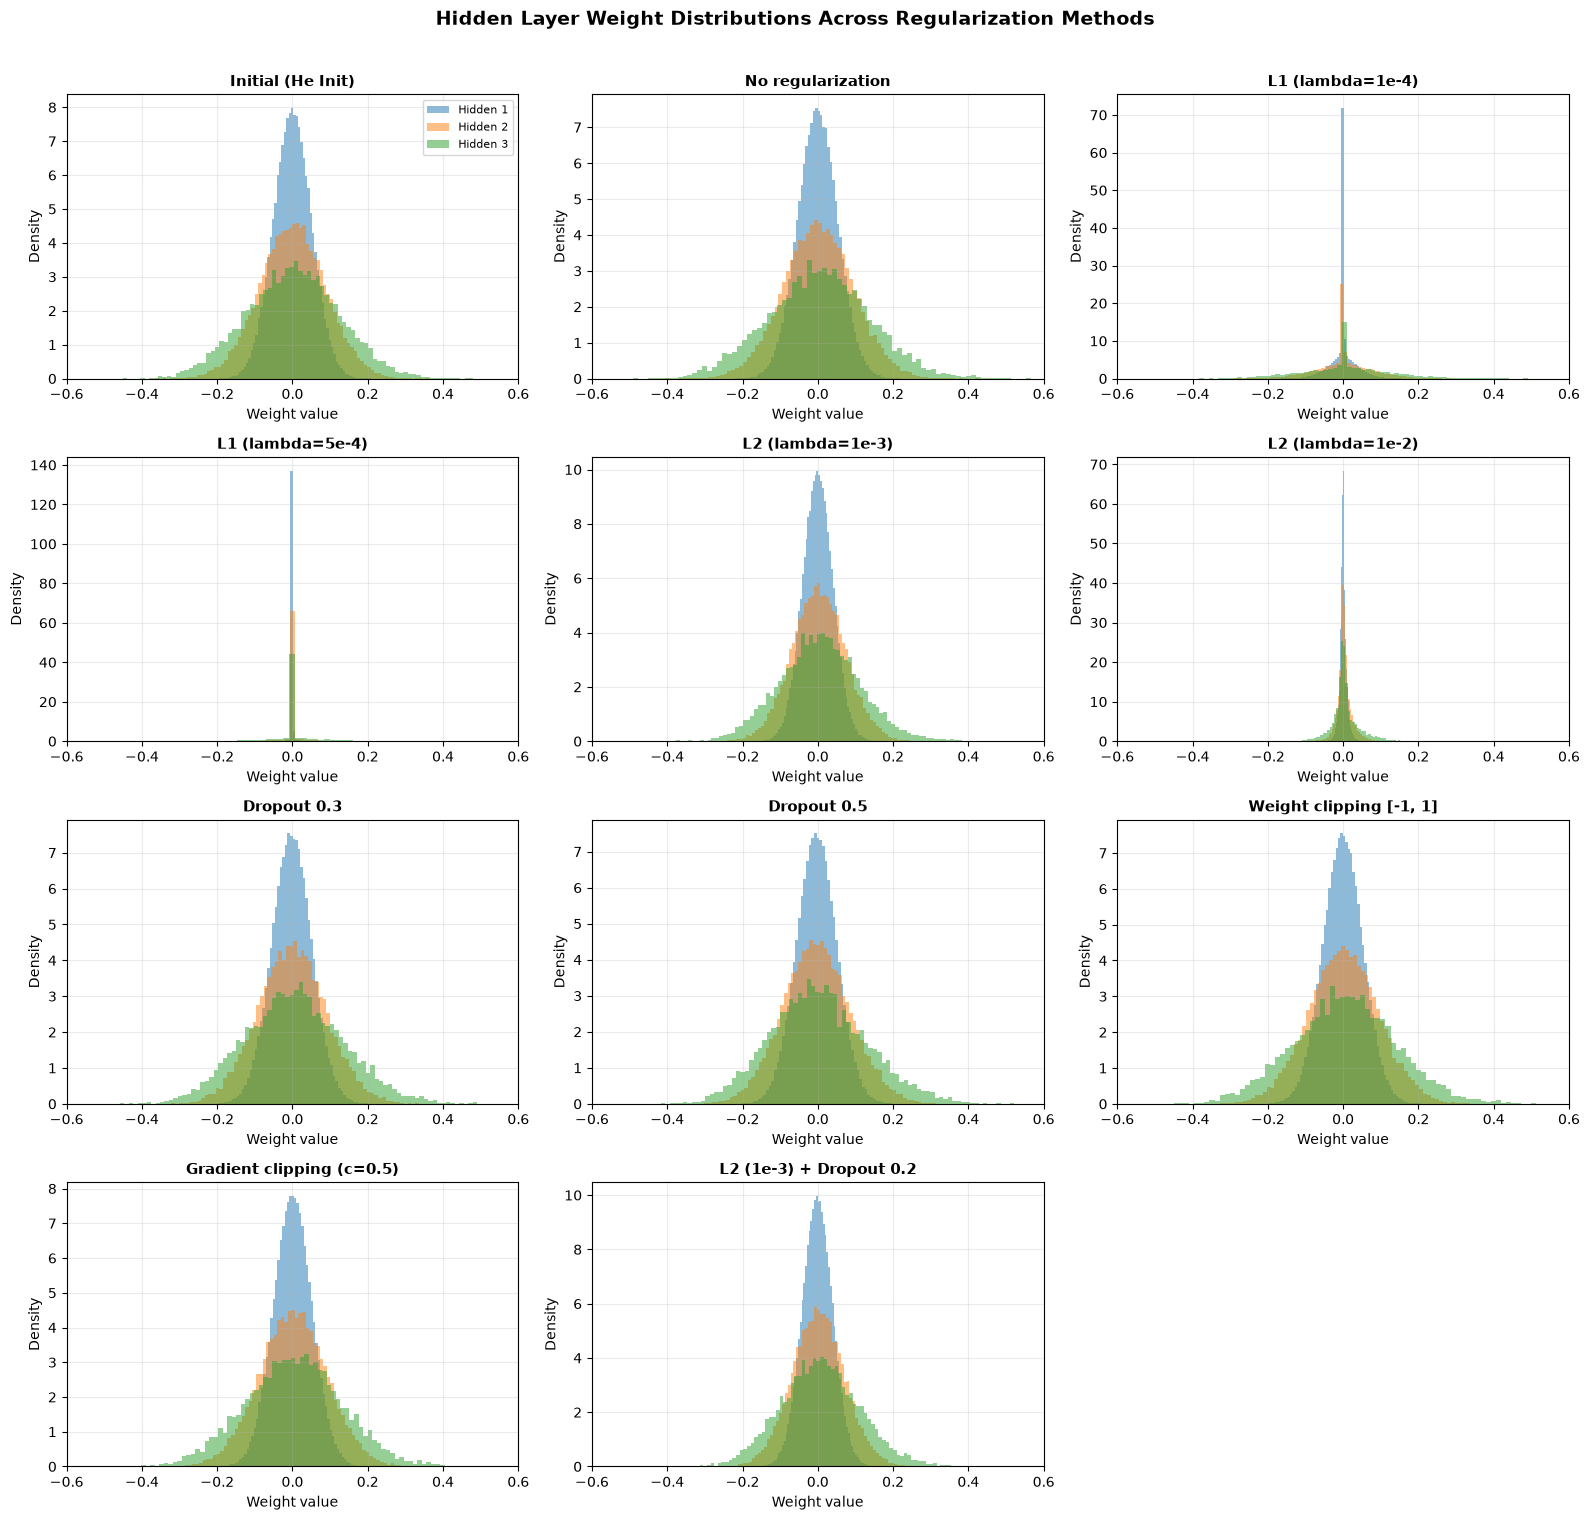

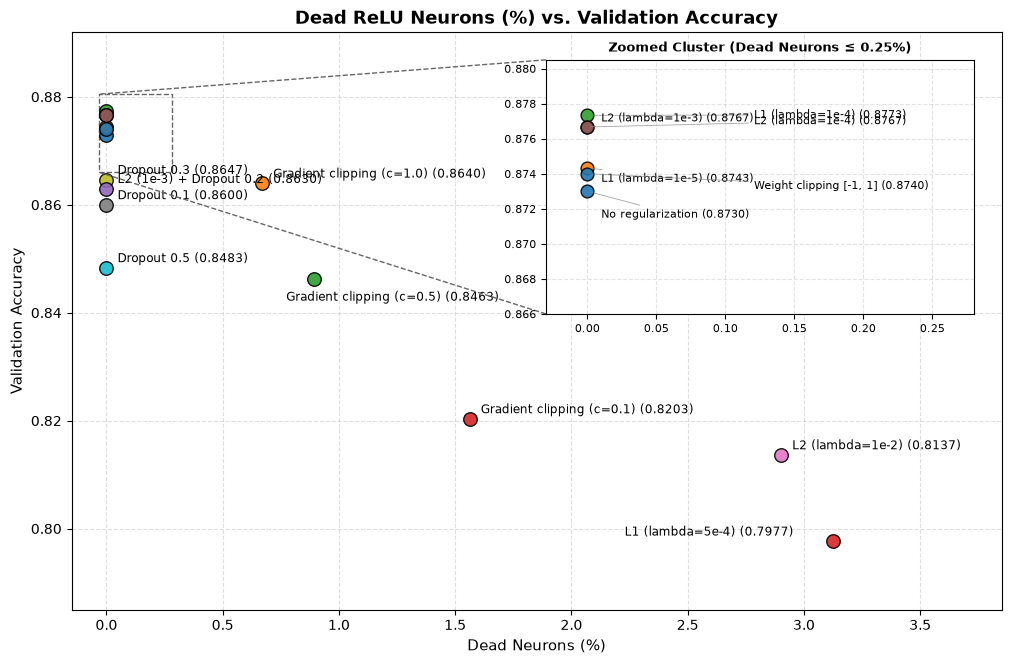

In [6]:
# --- Figure 1: Weight Distribution Histograms (Section 4.2) ---
hist_configs = [
    ("Initial (He Init)", initial_hidden_weights),
    ("No regularization", results_registry["No regularization"]["hidden_weights"]),
    ("L1 (lambda=1e-4)", results_registry["L1 (lambda=1e-4)"]["hidden_weights"]),
    ("L1 (lambda=5e-4)", results_registry["L1 (lambda=5e-4)"]["hidden_weights"]),
    ("L2 (lambda=1e-3)", results_registry["L2 (lambda=1e-3)"]["hidden_weights"]),
    ("L2 (lambda=1e-2)", results_registry["L2 (lambda=1e-2)"]["hidden_weights"]),
    ("Dropout 0.3", results_registry["Dropout 0.3"]["hidden_weights"]),
    ("Dropout 0.5", results_registry["Dropout 0.5"]["hidden_weights"]),
    ("Weight clipping [-1, 1]", results_registry["Weight clipping [-1, 1]"]["hidden_weights"]),
    ("Gradient clipping (c=0.5)", results_registry["Gradient clipping (c=0.5)"]["hidden_weights"]),
    ("L2 (1e-3) + Dropout 0.2", results_registry["L2 (1e-3) + Dropout 0.2"]["hidden_weights"]),
]

fig, axes = plt.subplots(4, 3, figsize=(16, 15))
axes = axes.ravel()

for idx, (title, w_list) in enumerate(hist_configs):
    ax = axes[idx]
    for l_idx, W in enumerate(w_list):
        ax.hist(
            W.ravel(),
            bins=80,
            density=True,
            alpha=0.5,
            label=f"Hidden {l_idx + 1}"
        )
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("Weight value")
    ax.set_ylabel("Density")
    ax.set_xlim(-0.6, 0.6)
    ax.grid(True, alpha=0.25)
    if idx == 0:
        ax.legend(fontsize=8)

# Hide unused 12th subplot
axes[-1].axis("off")

plt.suptitle("Hidden Layer Weight Distributions Across Regularization Methods", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# --- Figure 2: Clean non-overlapping labels for Dead Neurons (%) vs. Validation Accuracy ---
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

fig, ax = plt.subplots(figsize=(12, 7.5))

# 1. Plot all points on the main axes
for name in ordered_names:
    r = results_registry[name]
    ax.scatter(r["dead_pct"], r["val_acc"], s=95, alpha=0.9, edgecolors="black", zorder=3)

    # Label only well-separated points on the main plot (outside the top-left cluster)
    if not (r["dead_pct"] < 0.35 and r["val_acc"] > 0.865):
        if name == "Gradient clipping (c=0.5)":
            dx, dy = -20, -16
        elif name == "L1 (lambda=5e-4)":
            dx, dy = -150, 4
        else:
            dx, dy = 8, 4

        ax.annotate(
            f"{name} ({r['val_acc']:.4f})",
            (r["dead_pct"], r["val_acc"]),
            textcoords="offset points",
            xytext=(dx, dy),
            fontsize=8.5,
            zorder=4
        )

# 2. Create Inset Zoom Axes in the upper-right corner
axins = inset_axes(ax, width="46%", height="44%", loc="upper right", borderpad=2.0)

axins.set_xlim(-0.03, 0.28)
axins.set_ylim(0.866, 0.8805)
axins.grid(True, linestyle="--", alpha=0.35)
axins.set_title("Zoomed Cluster (Dead Neurons ≤ 0.25%)", fontsize=9.5, fontweight="bold")
axins.tick_params(labelsize=8)

cluster_offsets = {
    "L2 (lambda=1e-3)":          (10,   4),
    "L2 (lambda=1e-4)":          (120,  2),
    "Dropout 0.1":               (10,  -3),
    "L1 (lambda=1e-4)":          (120, -2),
    "L1 (lambda=1e-5)":          (10, -10),
    "Weight clipping [-1, 1]":   (120,-11),
    "No regularization":         (10, -19),
    "L2 (1e-3) + Dropout 0.2":   (-138, 10),
}

for name in ordered_names:
    r = results_registry[name]
    axins.scatter(r["dead_pct"], r["val_acc"], s=85, alpha=0.9, edgecolors="black", zorder=3)

    if name in cluster_offsets:
        dx, dy = cluster_offsets[name]
        axins.annotate(
            f"{name} ({r['val_acc']:.4f})",
            (r["dead_pct"], r["val_acc"]),
            textcoords="offset points",
            xytext=(dx, dy),
            fontsize=8,
            arrowprops=dict(arrowstyle="-", color="gray", lw=0.6, alpha=0.7),
            zorder=4
        )

mark_inset(ax, axins, loc1=2, loc2=3, fc="none", ec="0.4", linestyle="--", lw=1.0)

ax.set_title("Dead ReLU Neurons (%) vs. Validation Accuracy", fontsize=13, fontweight="bold")
ax.set_xlabel("Dead Neurons (%)", fontsize=11)
ax.set_ylabel("Validation Accuracy", fontsize=11)
ax.set_xlim(-0.15, 3.85)
ax.set_ylim(0.785, 0.892)
ax.grid(True, linestyle="--", alpha=0.4, zorder=0)

plt.show()

### 4.3 Analysis of Experimental Results and Research Questions

#### 1. Weight Distribution Analysis (Histograms)
* **Initial (He Initialization) vs. Unregularized Baseline:** Under He initialization, each layer has a distinct Gaussian variance $\sigma^2 = 2 / n_{in}$ (narrowest for Layer 1 with $n_{in}=784$, widest for Layer 3 with $n_{in}=64$). After 25 epochs of unregularized SGD, the distributions preserve their bell-shaped structure and spread slightly outward as weights grow to fit the training data, yielding a baseline sparsity ($|W_{ij}| < 0.01$) of **$13.76\%$**.
* **L1 vs. L2 Regularization:**
  * **L1 regularization** adds a constant subgradient $\lambda_1 \text{sign}(W)$ toward zero, producing a sharp Laplacian-like spike centered at $0.0$. At $\lambda_1 = 10^{-4}$, weight sparsity jumps from $13.76\%$ to **$48.53\%$** while improving validation accuracy to **$0.8773$** ($\text{CE Loss} = 0.3483$). At excessive strength ($\lambda_1 = 5 \cdot 10^{-4}$), **$94.28\%$** of all weights collapse near zero, severely degrading capacity ($\text{Val. Acc} = 0.7977$).
  * **L2 regularization** shrinks weights proportionally to their magnitude ($-\eta \lambda_2 W$), narrowing the Gaussian distribution smoothly without forcing exact zeros as aggressively as L1. Moderate L2 ($\lambda_2 = 10^{-3}$) achieves the lowest validation cross-entropy loss (**$0.3432$**, $\text{Val. Acc} = 0.8767$) with moderate sparsity (**$18.04\%$**). Excessive L2 ($\lambda_2 = 10^{-2}$) compresses weights tightly around zero ($\text{Sparsity} = 75.00\%$), causing underfitting ($\text{Val. Acc} = 0.8137$).
* **Weight Clipping ($[-1, 1]$):** Because He-initialized weights in a 4-layer network on normalized $[0, 1]$ inputs naturally remain within $[-0.45, 0.45]$, **$0 / 242,304$** weights reached the $\pm 1.0$ boundaries. Consequently, no boundary spikes appear in the histogram, and performance ($\text{Val. Acc} = 0.8740$, $\text{Sparsity} = 13.82\%$) matches the unregularized baseline. If the clipping interval were tighter (e.g., $[-0.1, 0.1]$), hard truncation would accumulate probability mass at the boundaries and restrict the network's representational scale, preventing it from reaching optimal weight magnitudes.
* **Gradient Clipping:** Unlike weight clipping, gradient clipping constrains the global L2-norm of the parameter updates rather than the weights directly. Consequently, the weight histograms retain the same shape and sparsity ($14.07\% - 14.35\%$) as the unregularized model. However, small thresholds ($c = 0.5, 0.1$) slow down convergence over a fixed 25-epoch budget, lowering validation accuracy to $0.8463$ and $0.8203$.

#### 2. Effect of Dropout and Combined Regularization (`L2 + Dropout`)
* **Why higher Dropout does not always improve quality:** Dropout introduces stochastic noise by randomly zeroing out a fraction $p$ of hidden units on every forward pass while keeping dead neurons at $0.00\%$ and weight sparsity near baseline ($13.71\% - 13.78\%$). Within a fixed 25-epoch SGD budget on a medium-sized MLP, `Dropout 0.1` ($0.8600$) and `Dropout 0.3` ($0.8647$) already slow convergence relative to the unregularized baseline ($0.8730$), while increasing $p$ to $0.5$ removes half of the hidden units per step, introducing excessive gradient variance and causing clear underfitting ($\text{Val. Acc}$ drops to **$0.8483$**, $\text{CE Loss} = 0.4237$).
* **Combined Regularization (`L2 (1e-3) + Dropout 0.2`):** Combining L2 weight decay with Dropout ($p = 0.2$) achieves $\text{Val. Acc} = 0.8630$ ($\text{CE Loss} = 0.3739$), $0.00\%$ dead neurons, and $18.12\%$ sparsity (mirroring L2's weight shrinkage). Compared to standalone `L2 (1e-3)` ($0.8767$, $\text{CE Loss} = 0.3432$), adding Dropout simultaneously over-constrains the model within 25 epochs, demonstrating that combining regularizers requires careful hyperparameter re-tuning or longer training rather than blindly stacking penalties.

#### 3. Dead Neurons vs. Validation Accuracy (Scatter Plot Analysis)
1. **Is there a relationship between dead neurons and classification quality?**  
   Yes—a clear negative trend appears once dead neurons exceed $0\%$: models with the highest validation accuracy ($0.8730 - 0.8773$) all have **$0.00\%$** dead neurons, whereas models with elevated dead neuron counts (`L2 = 1e-2` with $2.90\%$ dead neurons, `L1 = 5e-4` with $3.12\%$, and `Gradient clipping c=0.1` with $1.56\%$) suffer substantial accuracy drops ($0.8137$, $0.7977$, and $0.8203$). Notably, deeper layers (Layer 3 with 64 units) are most susceptible to neuron death ($7.81\% - 9.38\%$).
2. **Does a high number of dead neurons lead to lower accuracy?**  
   Yes. Dead ReLU neurons permanently output $0$ and receive zero gradient, permanently reducing the effective width and representational capacity of the network.
3. **Can models with the same percentage of dead neurons have different accuracies?**  
   Yes, clearly demonstrated along the vertical axis at **$0.00\%$ dead neurons**: ten different models share $0.00\%$ dead neurons yet span validation accuracies from **$0.8483$** (`Dropout 0.5`) to **$0.8773$** (`L1 = 1e-4`). Neuron survival alone does not guarantee optimal generalization if updates are too noisy (high Dropout) or unregularized.
4. **Is there an optimal balance between weight sparsity and dead neurons?**  
   Yes. Moderate sparsity achieved via well-tuned L1 ($\lambda_1 = 10^{-4} \rightarrow 48.53\%$ sparsity) or L2 ($\lambda_2 = 10^{-3} \rightarrow 18.04\%$ sparsity) eliminates redundant connections while keeping dead neurons at **$0.00\%$**, yielding peak validation accuracy ($0.8767 - 0.8773$). Pushing sparsity too far ($75\% - 94\%$) triggers neuron death ($2.90\% - 3.12\%$) and collapses accuracy.

#### 4. Generalization vs. Regularization Strength & Key Terminology
**Does increasing regularization strength always improve generalization?**  
**No.** Regularization follows an inverted-U (bias–variance trade-off) curve:
* **Weak / Moderate Regularization** (`L2 = 1e-4, 1e-3`; `L1 = 1e-5, 1e-4`) suppresses overfitting to noise in the training set and improves validation accuracy ($0.8743 - 0.8773$ vs. $0.8730$ baseline) while lowering cross-entropy loss ($0.3432 - 0.3587$ vs. $0.3625$).
* **Strong / Excessive Regularization** (`L2 = 1e-2`; `L1 = 5e-4`; `Dropout = 0.5`) overly restricts weight magnitudes or active sub-networks so the model cannot capture true decision boundaries within the training budget, resulting in **underfitting** (validation accuracy drops to $0.7977 - 0.8483$).

**Distinction Between Key Concepts:**
* **Small weight magnitude:** A parameter with a small absolute value (e.g., $|W_{ij}| \approx 0.02$) that still actively contributes to linear combinations and receives non-zero gradient updates.
* **Zero or near-zero weight:** A parameter whose magnitude falls below a sparsity threshold ($|W_{ij}| < 0.01$, or exact $0$ under L1), effectively pruning an individual synaptic connection without necessarily disabling the target neuron.
* **Inactive neuron:** A neuron whose ReLU output is $0$ for a *specific* input sample (or temporarily masked out by Dropout during a training step), while still activating ($Z > 0$) for other inputs in the dataset.
* **Dead neuron:** A ReLU neuron whose pre-activation $Z_{ij}^{(l)} \le 0$ for *every* sample in the dataset; it outputs $0$ universally, has zero local derivative ($f'(Z) = 0$), and can no longer learn via gradient descent.
* **Over-regularized model:** A model subjected to an excessively large penalty ($\lambda_1, \lambda_2$) or dropout rate ($p$) such that its effective capacity is crippled, leading to high bias, high training/validation loss, and underfitting.